# 04 — Ek deneyler

Bu defter, ana deneydeki yöntemleri değiştirmeden eşik, küme uzunluğu, sepet temizliği ve zaman etkisini inceler. Önce veri hazırlama ve ana yöntem defterleri çalıştırılmalıdır. Aynı çalışma dizinindeki `clean.json`, `mining.json` ve `data_audit.json` dosyaları kullanılır.

Bütün rastgele işlemlerde **SEED=7017** korunur. Sonraki dönem sonuçları daha önce incelendiğinden bunları yeni ve kör bir dış doğrulama olarak yorumlamıyoruz. Çıktılarda ham müşteri veya fatura kimliği gösterilmez.

In [1]:
import csv
import json
import math
import os
from collections import Counter, defaultdict
from datetime import datetime, timedelta
from itertools import combinations
from pathlib import Path
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7017
ROOT = Path.cwd()
if not (ROOT/'requirements.txt').is_file():
    ROOT = ROOT.parent
if not (ROOT/'requirements.txt').is_file():
    raise FileNotFoundError('Defteri proje kökünden veya notebooks klasöründen çalıştırın.')
WORK = Path(os.environ.get('RETAIL_NOTEBOOK_WORK', ROOT/'work'/'notebooks'))
WORK.mkdir(parents=True, exist_ok=True)
cache = WORK/'clean.json'
results = WORK


## Ortak hesaplamalar

Faturalar tam gün sınırlarıyla zaman sırasına ayrılır. ECLAT, aynı destek sayıları üzerinden sık kümeleri bulur. Kural metrikleri ana deneydeki formüllerle hesaplanır; bir ürünün aynı sepette birden fazla geçmesi desteği artırmaz.

In [2]:
def save(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')


def chronological_split(baskets):
    # Aynı gün ve aynı fatura bölünmez.
    first = baskets[int(len(baskets)*0.6)]['date'][:10]
    second = baskets[int(len(baskets)*0.8)]['date'][:10]
    train = [b for b in baskets if b['date'][:10] < first]
    valid = [b for b in baskets if first <= b['date'][:10] < second]
    test = [b for b in baskets if b['date'][:10] >= second]
    assert max(b['date'] for b in train) < min(b['date'] for b in valid)
    assert max(b['date'] for b in valid) < min(b['date'] for b in test)
    assert len(train)+len(valid)+len(test) == len(baskets)
    return train, valid, test


def eclat(transactions, support, max_len=3):
    minimum = math.ceil(support*len(transactions)-1e-10)
    vertical = defaultdict(set)
    for tid, transaction in enumerate(transactions):
        for item in transaction:
            vertical[item].add(tid)
    items = [(item, tids) for item, tids in sorted(vertical.items()) if len(tids)>=minimum]
    found = {}

    def visit(prefix, candidates):
        for index, (item, tids) in enumerate(candidates):
            new = prefix+(item,)
            found[frozenset(new)] = len(tids)
            if len(new) < max_len:
                following = []
                for other, other_tids in candidates[index+1:]:
                    overlap = tids & other_tids
                    if len(overlap) >= minimum:
                        following.append((other, overlap))
                visit(new, following)
    visit((), items)
    return found


def rules_from_counts(counts, n):
    result = []
    for items, joint in counts.items():
        if len(items) < 2:
            continue
        ordered = sorted(items)
        for length in range(1, len(items)):
            for left in combinations(ordered, length):
                a = frozenset(left)
                b = items-a
                confidence = joint/counts[a]
                consequent_support = counts[b]/n
                result.append(dict(antecedent=sorted(a), consequent=sorted(b),
                                   support=joint/n, confidence=confidence,
                                   lift=confidence/consequent_support,
                                   conviction=None if confidence == 1 else (1-consequent_support)/(1-confidence),
                                   conviction_infinite=confidence == 1,
                                   joint_count=joint))
    return result


def evaluate_rules(rules, transactions):
    index = defaultdict(set)
    for tid, row in enumerate(transactions):
        for item in row:
            index[item].add(tid)
    def tids(items):
        return set.intersection(*(index[item] for item in items))
    results = []
    for rule in rules:
        a, b = tids(rule['antecedent']), tids(rule['consequent'])
        both = len(a & b)
        confidence = both/len(a) if a else None
        lift = confidence/(len(b)/len(transactions)) if a and b else None
        results.append(dict(antecedent=rule['antecedent'], consequent=rule['consequent'],
                            antecedent_count=len(a), joint_count=both,
                            support=both/len(transactions), confidence=confidence, lift=lift))
    return results


## Kural seçimi ve gereksiz kurallar

Başlangıç politikası destek en az %2, güven en az %40 ve lift > 1 koşullarıdır. Gereksiz kural filtresi aynı sonuca sahip, daha uzun öncüllü bir kuralın güven kazandırıp kazandırmadığını kontrol eder. Ters yönlü kurallar ayrı önerilerdir ve otomatik olarak birleştirilmez.

In [3]:
def key(rule):
    return (tuple(rule['antecedent']), tuple(rule['consequent']))


def policy(rules, confidence=0.4, lift=1.0):
    selected = [r for r in rules if r['confidence'] >= confidence and r['lift'] > lift]
    return sorted(selected, key=lambda r: (-r['lift'], -r['support'], key(r)))


def prune_redundant(rules, tolerance=1e-12):
    """Aynı sonuç için bir alt öncül eşit/yüksek güven veriyorsa uzun öncül gereksizdir.

    Ters yönler birleştirilmez. Filtre yalnız eğitim metriklerini kullanır;
    bu sadeleştirme gelecekte eşit öneri başarısı garantisi değildir.
    """
    ordered = sorted(rules, key=lambda r: (len(r['antecedent']), key(r)))
    retained, removed = [], []
    for rule in ordered:
        dominator = next((other for other in retained
                          if other['consequent'] == rule['consequent']
                          and set(other['antecedent']) < set(rule['antecedent'])
                          and other['confidence'] + tolerance >= rule['confidence']), None)
        if dominator:
            removed.append(dict(rule=rule, dominated_by=dominator))
        else:
            retained.append(rule)
    return retained, removed


## Haftalık blok-bootstrap

Faturalar haftalık sayımlara çevrilir; boş haftalar da tutulur. Dört bitişik haftalık dairesel bloklar 1.000 kez yeniden örneklenir. Yüzdelik %95 aralıklar zamansal duyarlılığı gösterir. Tekrarlanan müşterilerin bağımlılığı ayrıca modellenmez ve dönem sonunun başına bağlanması yöntemin bir sınırlamasıdır.

In [4]:
def weekly_table(rows, rules):
    weeks = defaultdict(lambda: np.zeros((len(rules), 4), dtype=np.int64))
    for basket in rows:
        date = datetime.fromisoformat(basket['date']).date()
        monday = (date - timedelta(days=date.weekday())).isoformat()
        products = set(basket['products'])
        for i, rule in enumerate(rules):
            a = set(rule['antecedent']) <= products
            b = set(rule['consequent']) <= products
            weeks[monday][i] += [1, int(a), int(b), int(a and b)]
    # Boş haftalar takvimde korunur.
    first = datetime.fromisoformat(min(weeks)).date()
    last = datetime.fromisoformat(max(weeks)).date()
    ordered = []
    while first <= last:
        ordered.append(weeks[first.isoformat()])
        first += timedelta(days=7)
    return np.array(ordered)


def metrics_from_totals(totals):
    n, a, b, joint = np.moveaxis(np.asarray(totals, dtype=float), -1, 0)
    with np.errstate(divide='ignore', invalid='ignore'):
        support = joint/n
        confidence = joint/a
        lift = joint*n/(a*b)
    return support, confidence, lift


def moving_week_bootstrap(rows, rules, repetitions=1000, block_weeks=4, seed=SEED):
    table = weekly_table(rows, rules)
    weeks = len(table)
    rng = np.random.default_rng(seed)
    values = {name: [] for name in ['support', 'confidence', 'lift']}
    for _ in range(repetitions):
        starts = rng.integers(0, weeks, size=math.ceil(weeks/block_weeks))
        indices = ((starts[:,None]+np.arange(block_weeks)) % weeks).ravel()[:weeks]
        totals = table[indices].sum(axis=0)
        for name, metric in zip(values, metrics_from_totals(totals)):
            values[name].append(metric)
    result = []
    point = metrics_from_totals(table.sum(axis=0))
    for index, rule in enumerate(rules):
        record = dict(antecedent=rule['antecedent'], consequent=rule['consequent'])
        for j, name in enumerate(values):
            distribution = np.array(values[name])[:,index]
            distribution = distribution[np.isfinite(distribution)]
            estimate = float(point[j][index])
            record[name] = dict(estimate=estimate if np.isfinite(estimate) else None,
                                percentile_95=[float(x) for x in np.percentile(distribution,[2.5,97.5])] if len(distribution) else None,
                                finite_replicates=len(distribution))
        result.append(record)
    return dict(weeks=weeks, block_weeks=block_weeks, repetitions=repetitions,
                method='circular moving-block bootstrap of weekly aggregate counts; 4 adjacent weeks per block',
                limitation='Sensitivity interval, not a causal or fully calibrated inferential guarantee. Blocks approximate temporal dependence; repeated-customer dependence is not explicitly modeled. Circular wrap joins period endpoints. Test was previously inspected.',
                rules=result)


## Veriyi ve deney kimliğini kontrol et

Kaynak dosya ve seçilen fatura örnekleminin özetleri ana deneyle eşleşmelidir. Burada yalnız toplu sayılar gösterilir; sepetlerin ham kimlikleri çalışma belleğinde kalır.

In [5]:
data = json.loads(cache.read_text(encoding='utf-8'))
assert data['cache_policy']['seed'] == SEED, '01 notebook: SEED uyusmuyor'
assert data['sampling']['sampled_invoices'] == 50000
assert data['sha256'] == 'bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980'
main_result = json.loads((results/'mining.json').read_text(encoding='utf-8'))
audit = json.loads((results/'data_audit.json').read_text(encoding='utf-8'))
assert audit['source_sha256'] == data['sha256'], 'Source fingerprint mismatch'
assert audit['sampling']['selected_invoice_sha256'] == data['sampling']['selected_invoice_sha256'], 'Sample fingerprint mismatch'


## Ana kural politikasını yeniden doğrula

Eğitimden üretilen kuralların ana defterdeki kurallarla aynı olduğunu kontrol ediyoruz. Doğrulama veya test sonuçları bu seçimi değiştirmek için kullanılmaz.

In [6]:
train, valid, test = chronological_split(data['baskets'])
assert len(train) == main_result['training_baskets']
tx = [set(b['products']) for b in train]
vtx = [set(b['products']) for b in valid]
ttx = [set(b['products']) for b in test]
base_rules = policy(rules_from_counts(eclat(tx,.02,3),len(tx)))
assert {key(r) for r in base_rules} == {key(r) for r in main_result['rules']}
display({'eğitim_sepeti':len(train),'doğrulama_sepeti':len(valid),'test_sepeti':len(test),'başlangıç_kuralı':len(base_rules)})


{'eğitim_sepeti': 22066,
 'doğrulama_sepeti': 7345,
 'test_sepeti': 7413,
 'başlangıç_kuralı': 61}

## Destek ve küme uzunluğu duyarlılığı

En büyük küme uzunluğunu 2, 3 ve 4; destek eşiğini %1 ve %2 olarak karşılaştırıyoruz. Kural sayısı artışı tek başına daha iyi öneri anlamına gelmez. Süreler donanıma ve o andaki iş yüküne bağlıdır.

In [7]:
sensitivity = []
all_counts = {}
for support in [.01,.02]:
    for length in [2,3,4]:
        start = perf_counter()
        counts = eclat(tx,support,length)
        all_counts[(support,length)] = counts
        selected = policy(rules_from_counts(counts,len(tx)))
        sensitivity.append(dict(min_support=support,max_len=length,itemsets=len(counts),
                                itemsets_by_length=dict(Counter(len(items) for items in counts)),
                                rules=len(selected),seconds=perf_counter()-start))
        print('Destek/uzunluk deneyi:', sensitivity[-1])
display(sensitivity)


Destek/uzunluk deneyi: {'min_support': 0.01, 'max_len': 2, 'itemsets': 1313, 'itemsets_by_length': {1: 732, 2: 581}, 'rules': 328, 'seconds': 2.2026734000028227}


Destek/uzunluk deneyi: {'min_support': 0.01, 'max_len': 3, 'itemsets': 1402, 'itemsets_by_length': {1: 732, 2: 581, 3: 89}, 'rules': 583, 'seconds': 2.1162387000003946}


Destek/uzunluk deneyi: {'min_support': 0.01, 'max_len': 4, 'itemsets': 1405, 'itemsets_by_length': {1: 732, 2: 581, 3: 89, 4: 3}, 'rules': 608, 'seconds': 2.2083449000056135}


Destek/uzunluk deneyi: {'min_support': 0.02, 'max_len': 2, 'itemsets': 331, 'itemsets_by_length': {1: 274, 2: 57}, 'rules': 61, 'seconds': 0.5883304999952088}


Destek/uzunluk deneyi: {'min_support': 0.02, 'max_len': 3, 'itemsets': 331, 'itemsets_by_length': {1: 274, 2: 57}, 'rules': 61, 'seconds': 0.5893136000013328}


Destek/uzunluk deneyi: {'min_support': 0.02, 'max_len': 4, 'itemsets': 331, 'itemsets_by_length': {1: 274, 2: 57}, 'rules': 61, 'seconds': 0.6007854999988922}


[{'min_support': 0.01,
  'max_len': 2,
  'itemsets': 1313,
  'itemsets_by_length': {1: 732, 2: 581},
  'rules': 328,
  'seconds': 2.2026734000028227},
 {'min_support': 0.01,
  'max_len': 3,
  'itemsets': 1402,
  'itemsets_by_length': {1: 732, 2: 581, 3: 89},
  'rules': 583,
  'seconds': 2.1162387000003946},
 {'min_support': 0.01,
  'max_len': 4,
  'itemsets': 1405,
  'itemsets_by_length': {1: 732, 2: 581, 3: 89, 4: 3},
  'rules': 608,
  'seconds': 2.2083449000056135},
 {'min_support': 0.02,
  'max_len': 2,
  'itemsets': 331,
  'itemsets_by_length': {1: 274, 2: 57},
  'rules': 61,
  'seconds': 0.5883304999952088},
 {'min_support': 0.02,
  'max_len': 3,
  'itemsets': 331,
  'itemsets_by_length': {1: 274, 2: 57},
  'rules': 61,
  'seconds': 0.5893136000013328},
 {'min_support': 0.02,
  'max_len': 4,
  'itemsets': 331,
  'itemsets_by_length': {1: 274, 2: 57},
  'rules': 61,
  'seconds': 0.6007854999988922}]

## Sepet temizleme etkisi

İki alternatif eğitim kümesi denenir: tek ürünlü sepetleri çıkarmak ve en büyük %1 sepeti çıkarmak. Doğrulama sepetleri sabit kalır. Eğitimde paydanın değişmesi destek ve lift değerlerini etkileyebileceği için daha fazla kuralı doğrudan başarı artışı saymıyoruz.

In [8]:
n_remove = math.ceil(.01*len(train))
largest_ids = {b['invoice'] for b in sorted(train,key=lambda b:(-len(b['products']),b['date'],b['invoice']))[:n_remove]}
variants = [('baseline',train),('remove_single_product_baskets',[b for b in train if len(b['products'])>1]),
            ('remove_largest_one_percent_baskets',[b for b in train if b['invoice'] not in largest_ids])]
baseline_keys = {key(r) for r in base_rules}
ablations = []
for name, rows in variants:
    rows_tx = [set(b['products']) for b in rows]
    rules = policy(rules_from_counts(eclat(rows_tx,.02,3),len(rows_tx)))
    ids = {key(r) for r in rules}
    evaluated = evaluate_rules(rules,vtx)
    eligible = [r for r in evaluated if r['antecedent_count']>=20]
    passes = [r for r in eligible if r['confidence']>=.4 and r['lift'] is not None and r['lift']>1]
    ablations.append(dict(variant=name,training_baskets=len(rows),removed_training_baskets=len(train)-len(rows),
                          training_rules=len(rules),baseline_rule_jaccard=len(ids & baseline_keys)/len(ids|baseline_keys) if ids|baseline_keys else 1,
                          validation_eligible_rules=len(eligible),validation_passing_rules=len(passes),
                          note='All original validation baskets retained; denominator changes only in altered training data. This is a sensitivity study, not selection of a final preprocessing policy.'))
display(ablations)


[{'variant': 'baseline',
  'training_baskets': 22066,
  'removed_training_baskets': 0,
  'training_rules': 61,
  'baseline_rule_jaccard': 1.0,
  'validation_eligible_rules': 60,
  'validation_passing_rules': 47,
  'note': 'All original validation baskets retained; denominator changes only in altered training data. This is a sensitivity study, not selection of a final preprocessing policy.'},
 {'variant': 'remove_single_product_baskets',
  'training_baskets': 20147,
  'removed_training_baskets': 1919,
  'training_rules': 89,
  'baseline_rule_jaccard': 0.6853932584269663,
  'validation_eligible_rules': 87,
  'validation_passing_rules': 68,
  'note': 'All original validation baskets retained; denominator changes only in altered training data. This is a sensitivity study, not selection of a final preprocessing policy.'},
 {'variant': 'remove_largest_one_percent_baskets',
  'training_baskets': 21845,
  'removed_training_baskets': 221,
  'training_rules': 34,
  'baseline_rule_jaccard': 0.557

## İşe yaramayan eşik denemeleri

Çok yaygın örüntüleri aramak için destek %10, kusursuz eğitim birlikteliklerini aramak için güven %100 denenir. Aşağıdaki sonuçlar hesaplanır; kural çıkarsa deney otomatik olarak başarısız ilan edilmez.

In [9]:
high_counts = eclat(tx,.10,3)
high_rules = policy(rules_from_counts(high_counts,len(tx)))
certainty_rules = policy(rules_from_counts(all_counts[(.02,3)],len(tx)),confidence=1.0)
failed = [dict(name='Minimum support 10%',reason_tried='Prefer common, well-supported cross-sell patterns.',
               actual=dict(itemsets=len(high_counts),rules=len(high_rules)),
               outcome='No actionable cross-sell rules under this training-only threshold.' if not high_rules else 'Rules retained; this cannot be honestly classified as a complete failure.',
               is_failed_for_cross_sell_objective=not bool(high_rules)),
          dict(name='Minimum confidence 100%',reason_tried='Seek perfectly reliable training associations.',
               actual=dict(rules=len(certainty_rules)),
               outcome='No rules survive; perfect training confidence is too restrictive at support >= 2%.' if not certainty_rules else 'Some rules survive; perfection on training is not proof of future reliability.',
               is_failed_for_cross_sell_objective=not bool(certainty_rules))]
display(failed)


[{'name': 'Minimum support 10%',
  'reason_tried': 'Prefer common, well-supported cross-sell patterns.',
  'actual': {'itemsets': 2, 'rules': 0},
  'outcome': 'No actionable cross-sell rules under this training-only threshold.',
  'is_failed_for_cross_sell_objective': True},
 {'name': 'Minimum confidence 100%',
  'reason_tried': 'Seek perfectly reliable training associations.',
  'actual': {'rules': 0},
  'outcome': 'No rules survive; perfect training confidence is too restrictive at support >= 2%.',
  'is_failed_for_cross_sell_objective': True}]

## Gereksiz kuralları filtrele

Destek %1 ve en fazla dört ürün kapsamındaki kuralları sadeleştiriyoruz. Sonraki zaman analizi için ilk üç kural yalnız eğitim lift sırasından seçilir; zıt yönler korunur.

In [10]:
relaxed = policy(rules_from_counts(all_counts[(.01,4)],len(tx)))
retained, removed = prune_redundant(relaxed)
selected = base_rules[:3]  # Sıralama yalnız eğitim verisinden gelir.
display({'önce':len(relaxed),'sonra':len(retained),'elenen':len(removed)})


{'önce': 608, 'sonra': 607, 'elenen': 1}

## Aylık değişim

Eğitimde seçilen üç kuralın her aydaki destek, güven ve lift değerleri hesaplanır. Aylık çizimde öncülün 20'den az görüldüğü noktalar gösterilmez; küçük sayımlar güçlü bir değişim kanıtı sayılmaz.

In [11]:
monthly = []
grouped = defaultdict(list)
for basket in data['baskets']:
    grouped[basket['date'][:7]].append(set(basket['products']))
for month, rows in sorted(grouped.items()):
    values = evaluate_rules(selected,rows)
    for rule in values:
        monthly.append(dict(month=month,invoices=len(rows),**rule))


## Dönemler arası kararlılık

Başlangıçtaki bütün kurallar eğitim, doğrulama ve test dönemlerinde aynı eşiklerle değerlendirilir. En az 20 öncül gözlemi olan kurallar ayrı sayılır. Daha önce incelenmiş test dönemi yeni bir dış doğrulama değildir.

In [12]:
temporal_summary = {}
for name, rows in [('train',tx),('validation',vtx),('test',ttx)]:
    evaluated = evaluate_rules(base_rules,rows)
    enough = [r for r in evaluated if r['antecedent_count']>=20]
    passes = [r for r in enough if r['confidence']>=.4 and r['lift'] is not None and r['lift']>1]
    temporal_summary[name] = dict(invoices=len(rows),eligible_rules=len(enough),passing_rules=len(passes),
                                  evaluated_rules=len(evaluated),mean_confidence=float(np.mean([r['confidence'] for r in enough])),
                                  mean_lift=float(np.mean([r['lift'] for r in enough if r['lift'] is not None])))
display(temporal_summary)


{'train': {'invoices': 22066,
  'eligible_rules': 61,
  'passing_rules': 61,
  'evaluated_rules': 61,
  'mean_confidence': 0.5191118809097289,
  'mean_lift': 8.775996966084689},
 'validation': {'invoices': 7345,
  'eligible_rules': 60,
  'passing_rules': 47,
  'evaluated_rules': 61,
  'mean_confidence': 0.49262244932925253,
  'mean_lift': 9.037173999699581},
 'test': {'invoices': 7413,
  'eligible_rules': 61,
  'passing_rules': 50,
  'evaluated_rules': 61,
  'mean_confidence': 0.5051834525974286,
  'mean_lift': 10.534740117494453}}

## Sonraki dönemlerde belirsizlik aralıkları

Aynı üç eğitim kuralı için doğrulama ve test dönemlerinde blok-bootstrap aralıkları hesaplanır. Bunlar sabit seçilmiş kuralların duyarlılık aralıklarıdır; nedensel sonuç veya bütün belirsizliği kapsayan bir garanti olarak yorumlanmaz.

In [13]:
bootstrap_validation = moving_week_bootstrap(valid, selected)
bootstrap_test = moving_week_bootstrap(test, selected)
display({'doğrulama':bootstrap_validation,'test':bootstrap_test})


{'doğrulama': {'weeks': 25,
  'block_weeks': 4,
  'repetitions': 1000,
  'method': 'circular moving-block bootstrap of weekly aggregate counts; 4 adjacent weeks per block',
  'limitation': 'Sensitivity interval, not a causal or fully calibrated inferential guarantee. Blocks approximate temporal dependence; repeated-customer dependence is not explicitly modeled. Circular wrap joins period endpoints. Test was previously inspected.',
  'rules': [{'antecedent': ['84997C'],
    'consequent': ['84997D'],
    'support': {'estimate': 0.009530292716133424,
     'percentile_95': [0.006540488803770307, 0.011845707873558254],
     'finite_replicates': 1000},
    'confidence': {'estimate': 0.6862745098039216,
     'percentile_95': [0.613820973934128, 0.7582512315270935],
     'finite_replicates': 1000},
    'lift': {'estimate': 32.10628200324716,
     'percentile_95': [27.631999461420005, 36.87857362208375],
     'finite_replicates': 1000}},
   {'antecedent': ['84997D'],
    'consequent': ['84997C'

## Toplu sonuçları kaydet

JSON ve CSV yalnız deney özetleriyle ürün kural metriklerini içerir. Dosyalar `WORK` dizinine yazılır; proje kökündeki ana sonuçlar ve ara rapor değiştirilmez.

In [14]:
out = dict(seed=SEED,source_sha256=data['sha256'],sample_fingerprint=data['sampling']['selected_invoice_sha256'],
           protocol='All thresholds and variants are specified in code; training rules define later-period evaluation. No variant is selected using test metrics. Previously inspected test is an exploratory temporal check, not a new external holdout.',
           length_sensitivity=sensitivity,ablation=ablations,unsuccessful_experiments=failed,
           redundancy_filter=dict(min_support=.01,max_len=4,before=len(relaxed),after=len(retained),removed=len(removed),
                                  definition=prune_redundant.__doc__,examples=removed[:10]),
           temporal_summary=temporal_summary,monthly_selected_rules=monthly,
           bootstrap_validation=bootstrap_validation,bootstrap_test=bootstrap_test,
           selected_rule_basis='Top three training lift-ranked rules at support >= 2%, confidence >= 40%, lift > 1. Reciprocal directions retained.',
           metric_note='Algorithm itemsets are identical at matching settings: quality differences are not attributed to Apriori/FP-Growth/ECLAT. Runtime measurements are implementation and environment dependent.')
save(results/'extended.json',out)
csv_rows = [dict(section='length_sensitivity',**r) for r in sensitivity]+[dict(section='ablation',**r) for r in ablations]
fields = sorted({field for row in csv_rows for field in row})
with (results/'extended_summary.csv').open('w',encoding='utf-8-sig',newline='') as handle:
    writer = csv.DictWriter(handle,fieldnames=fields)
    writer.writeheader(); writer.writerows(csv_rows)


## Grafik kaydetme ayarı

Grafikler defter içinde gösterilir; aynı çizimler PNG ve JPEG olarak `WORK/figures` altına kaydedilir.

In [15]:
figures = results/'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
def figure_save(fig,name):
    fig.tight_layout()
    fig.savefig(figures/f'{name}.png',dpi=170)
    fig.savefig(figures/f'{name}.jpeg',dpi=170,pil_kwargs={'quality':95,'subsampling':0})
    display(fig)
    plt.close(fig)


## Grafik: temizleme tercihleri

Grafik, eğitim verisinden çıkarılan sepetlerin kural sayısını nasıl değiştirdiğini gösterir. Varyantların doğrulama sayıları üstteki tabloda birlikte okunmalıdır.

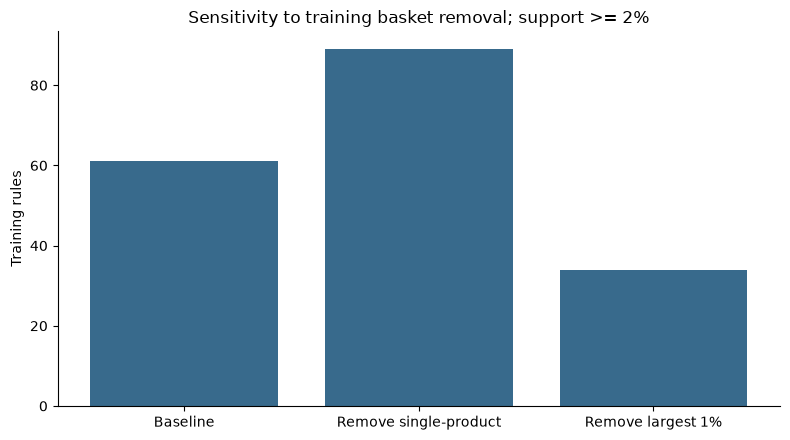

In [16]:
fig,ax = plt.subplots(figsize=(8,4.5))
ax.bar(['Baseline','Remove single-product','Remove largest 1%'],[r['training_rules'] for r in ablations],color='#386a8c')
ax.set(ylabel='Training rules',title='Sensitivity to training basket removal; support >= 2%')
figure_save(fig,'extended_ablation')


## Grafik: aylık güven değişimi

Başlangıç güven eşiği %40'tır. Özellikle düşük sayımlı veya mevsimsel aylarda tek bir noktadan kalıcı davranış değişimi sonucu çıkarılmaz.

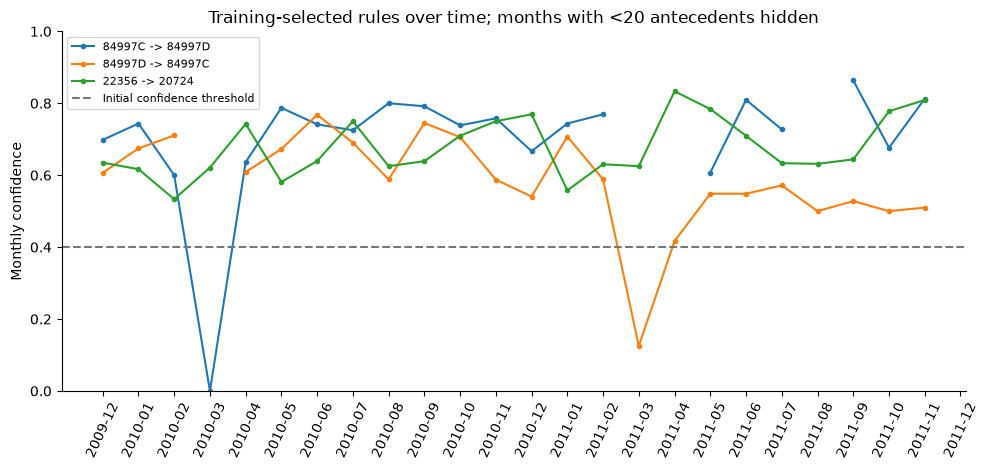

In [17]:
fig,ax = plt.subplots(figsize=(10,4.8))
for rule in selected:
    rows = [r for r in monthly if key(r)==key(rule)]
    ax.plot([r['month'] for r in rows],[r['confidence'] if r['antecedent_count']>=20 else np.nan for r in rows],marker='.',label=f'{"+".join(rule["antecedent"])} -> {"+".join(rule["consequent"])}')
ax.axhline(.4,color='#777777',linestyle='--',label='Initial confidence threshold')
ax.set(ylabel='Monthly confidence',title='Training-selected rules over time; months with <20 antecedents hidden',ylim=(0,1))
ax.tick_params(axis='x',rotation=65); ax.legend(fontsize=8)
figure_save(fig,'extended_monthly_stability')


## Grafik: küme uzunluğu

Destek eşiği düşük olduğunda daha uzun ürün kümeleri ek kurallar getirebilir. Aynı destek ve kapsamda algoritmaların aynı kümeleri bulması beklendiğinden kural kalitesi farkını algoritma adlarına bağlamıyoruz.

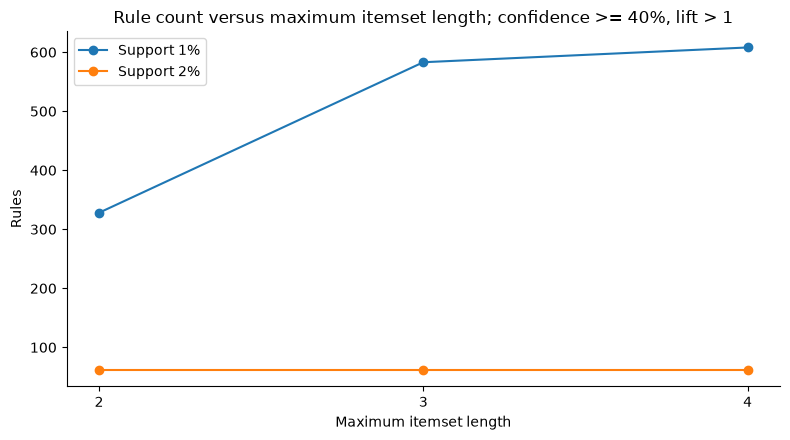

Ek deneyler kaydedildi: C:\Users\gokha\Documents\Codex\2026-11-02\skill-2\work\notebook-run\extended.json


In [18]:
fig,ax = plt.subplots(figsize=(8,4.5))
for support in [.01,.02]:
    rows=[r for r in sensitivity if r['min_support']==support]
    ax.plot([r['max_len'] for r in rows],[r['rules'] for r in rows],marker='o',label=f'Support {support:.0%}')
ax.set(xticks=[2,3,4],xlabel='Maximum itemset length',ylabel='Rules',title='Rule count versus maximum itemset length; confidence >= 40%, lift > 1')
ax.legend()
figure_save(fig,'extended_length_sensitivity')

print('Ek deneyler kaydedildi:', results/'extended.json')
